<a href="https://colab.research.google.com/github/chittaragipriyanka-sudo/BRANCH/blob/main/LAB_5_Outlier_Detection_and_Treatment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
data = {
    "Student": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J","K","L","M","N","O"],
    "Study_hours": [2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}
df = pd.DataFrame(data)
print("Original dataset")
display(df)

Original dataset


,Student,Study_hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["Study_hours"].describe()

,Study_hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


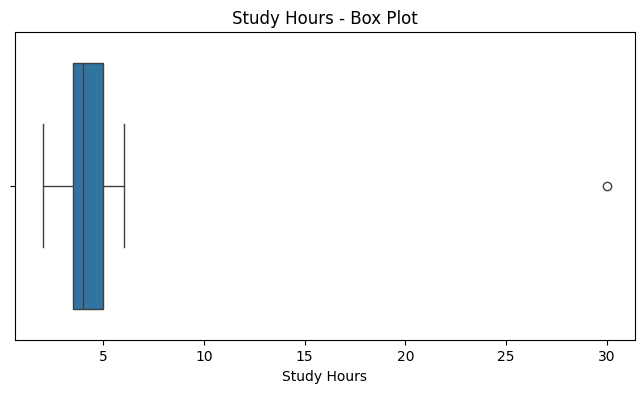

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_hours"])
plt.title("Study Hours - Box Plot")
plt.xlabel("Study Hours")
plt.show()

In [ ]:
Q1 = df["Study_hours"].quantile(0.25)
Q3 = df["Study_hours"].quantile(0.75)
print("Q1:",Q1)
print("Q3:",Q3)

Q1: 3.5
Q3: 5.0


IQR Method

In [ ]:
IQR = Q3 - Q1
print("IQR:",IQR)

IQR: 1.5


In [ ]:
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 1.25
Upper Bound: 7.25


In [ ]:
outliers_iqr=df[
    (df["Study_hours"]<lower_bound) |
     (df["Study_hours"]>upper_bound)]
print("Outliers using IQR Method:")
display(outliers_iqr)

Outliers using IQR Method:


,Student,Study_hours
13,N,30


In [ ]:
normal_data_iqr = df[
    (df["Study_hours"] >= lower_bound) &
    (df["Study_hours"] <= upper_bound)
]
display(normal_data_iqr)


,Student,Study_hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [ ]:
df["z_score"] = zscore(df["Study_hours"])
print("Dataset with z-scores")
display(df)

Dataset with z-scores


,Student,Study_hours,z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [ ]:
z_outliers=df[
    (df["z_score"]>3) |
    (df["z_score"]<-3)
]
print("Z-Score Outliers")
display(z_outliers)


Z-Score Outliers


,Student,Study_hours,z_score
13,N,30,3.687515


In [ ]:
print("IQR Outliers:")
display(outliers_iqr)
print("Z-Score Outliers:")
display(z_outliers)

IQR Outliers:


,Student,Study_hours
13,N,30


Z-Score Outliers:


,Student,Study_hours,z_score
13,N,30,3.687515


outlier removal

In [ ]:
df_without_outliers = df[
    (df["Study_hours"] >= lower_bound) &
    (df["Study_hours"] <= upper_bound)
]

display(df_without_outliers)

Dataset without Outliers:


,Student,Study_hours,z_score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


capping means adding another value in place of it

In [ ]:
df_capped = df.copy()
df_capped["Study_hours"]=df_capped["Study_hours"].clip(
    lower=lower_bound,
    upper=upper_bound
)
display(df_capped)

,Student,Study_hours,z_score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


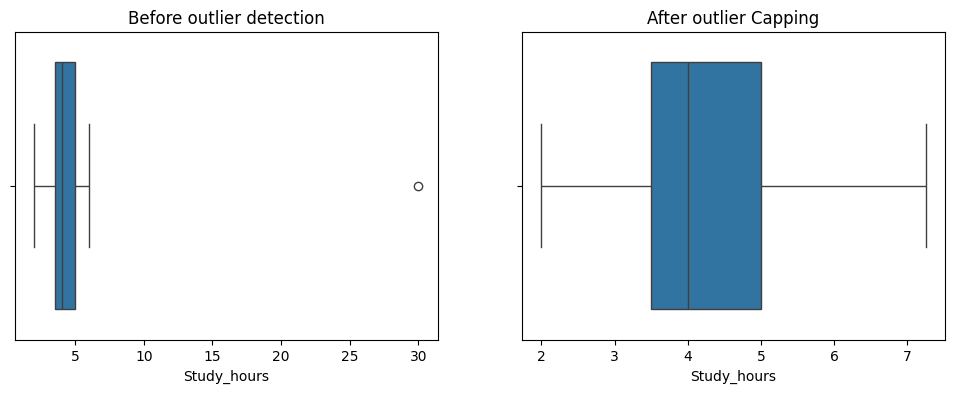

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.boxplot(x=df["Study_hours"])
plt.title("Before outlier detection")
plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_hours"])
plt.title("After outlier Capping")
plt.show()
